# Story 5 — Can Chicago Be a Model for Other U.S. Cities?

**Research question:** Does Chicago demonstrate a **repeatable analytical workflow** for combining complaint and inspection records that another city might adapt?

**Boundaries:** This is an **implementation-feasibility case study using Chicago data only**. No records from other U.S. cities were supplied. The charts cannot validate transferability, predict other cities’ performance, or prove a policy would work. Focus on coverage, data quality, matching tradeoffs, and the out-of-time warning test.

## Setup and embedded verified aggregates

All figures below are computed from **aggregated results derived from the five user-provided Chicago ZIP archives**, with duplicate request IDs and inspection IDs removed. Figures are embedded in this executed notebook and can be recalculated **without uploading raw ZIPs**. All estimates refer to **2011–2025 complete comparison years**, unless explicitly noted. See the README for methodology. ZIP codes are only proxies for neighborhoods; same ZIP/address is not proof a 311 complaint relates to a specific food establishment.

In [1]:
import json
import builtins
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9.3,4.6),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BLUE='#28679c'; TEAL='#18877b'; ORANGE='#e19531'; RED='#c95756'; GREY='#7c8791'
def pct(x, n): return 100*x/n if n else np.nan
def style(ax, title, ylabel=None, xlabel=None):
    ax.set_title(title,loc='left',pad=14,fontsize=12)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.grid(axis='y',alpha=.18)
    ax.set_axisbelow(True)
    plt.tight_layout()
def show():
    plt.show()

quality = pd.DataFrame(json.loads(r'''[{"field":"Event date","311_pct":100.0,"food_pct":100.0},{"field":"ZIP (valid 5-digit)","311_pct":95.45724442051761,"food_pct":99.99895024144448},{"field":"Nonblank address","311_pct":99.96318610413978,"food_pct":100.0}]'''))
annual = pd.DataFrame(json.loads(r'''[{"year":2011,"complaints":17922,"inspections":18706,"graded":17547,"fails":4346,"conditional":1516,"fail_pct":24.76776656978401,"conditional_pct":8.639653502023139},{"year":2012,"complaints":19122,"inspections":18815,"graded":15979,"fails":3635,"conditional":1530,"fail_pct":22.74860754740597,"conditional_pct":9.575067275799487},{"year":2013,"complaints":17939,"inspections":20918,"graded":17050,"fails":3343,"conditional":1755,"fail_pct":19.607038123167154,"conditional_pct":10.29325513196481},{"year":2014,"complaints":18842,"inspections":21516,"graded":18600,"fails":3711,"conditional":2308,"fail_pct":19.951612903225808,"conditional_pct":12.408602150537634},{"year":2015,"complaints":19274,"inspections":20894,"graded":17877,"fails":3605,"conditional":2155,"fail_pct":20.165575879621862,"conditional_pct":12.054595290037478},{"year":2016,"complaints":20927,"inspections":22795,"graded":19843,"fails":4294,"conditional":2633,"fail_pct":21.639873003074133,"conditional_pct":13.269162928992591},{"year":2017,"complaints":19703,"inspections":21534,"graded":18455,"fails":4110,"conditional":2131,"fail_pct":22.27038742888106,"conditional_pct":11.547006231373611},{"year":2018,"complaints":17944,"inspections":17158,"graded":14824,"fails":3315,"conditional":5154,"fail_pct":22.362385321100916,"conditional_pct":34.76794387479762},{"year":2019,"complaints":12260,"inspections":19027,"graded":16099,"fails":3608,"conditional":7927,"fail_pct":22.41132989626685,"conditional_pct":49.23908317286788},{"year":2020,"complaints":14965,"inspections":15095,"graded":12578,"fails":2926,"conditional":3927,"fail_pct":23.26283987915408,"conditional_pct":31.221179837812052},{"year":2021,"complaints":18453,"inspections":15833,"graded":13109,"fails":3027,"conditional":3181,"fail_pct":23.09100617896102,"conditional_pct":24.2657716072927},{"year":2022,"complaints":14066,"inspections":16912,"graded":14263,"fails":3547,"conditional":2499,"fail_pct":24.868540980158453,"conditional_pct":17.520858164481524},{"year":2023,"complaints":13111,"inspections":18232,"graded":15391,"fails":3831,"conditional":2351,"fail_pct":24.89117016438178,"conditional_pct":15.27516080826457},{"year":2024,"complaints":13602,"inspections":19184,"graded":15957,"fails":3478,"conditional":2602,"fail_pct":21.79607695682146,"conditional_pct":16.30632324371749},{"year":2025,"complaints":14492,"inspections":19161,"graded":16024,"fails":3384,"conditional":2275,"fail_pct":21.11832251622566,"conditional_pct":14.197453819271093}]'''))
matching_year = pd.DataFrame(json.loads(r'''[{"year":2011,"address_years":8891,"matched":437,"graded":17547,"fails":4346,"match_pct":4.915082667866382},{"year":2012,"address_years":9433,"matched":382,"graded":15979,"fails":3635,"match_pct":4.049613060532174},{"year":2013,"address_years":10839,"matched":427,"graded":17050,"fails":3343,"match_pct":3.9394778116062366},{"year":2014,"address_years":10619,"matched":427,"graded":18600,"fails":3711,"match_pct":4.021094264996704},{"year":2015,"address_years":10775,"matched":438,"graded":17877,"fails":3605,"match_pct":4.064965197215777},{"year":2016,"address_years":10842,"matched":422,"graded":19843,"fails":4294,"match_pct":3.892270798745619},{"year":2017,"address_years":10432,"matched":466,"graded":18455,"fails":4110,"match_pct":4.4670245398773005},{"year":2018,"address_years":8689,"matched":305,"graded":14824,"fails":3315,"match_pct":3.5101852917481873},{"year":2019,"address_years":10069,"matched":338,"graded":16099,"fails":3608,"match_pct":3.356837819048565},{"year":2020,"address_years":8605,"matched":380,"graded":12578,"fails":2926,"match_pct":4.416037187681581},{"year":2021,"address_years":8360,"matched":424,"graded":13109,"fails":3027,"match_pct":5.07177033492823},{"year":2022,"address_years":8918,"matched":374,"graded":14263,"fails":3547,"match_pct":4.193765418255214},{"year":2023,"address_years":9466,"matched":395,"graded":15391,"fails":3831,"match_pct":4.172829072469892},{"year":2024,"address_years":10080,"matched":429,"graded":15957,"fails":3478,"match_pct":4.255952380952381},{"year":2025,"address_years":9950,"matched":421,"graded":16024,"fails":3384,"match_pct":4.231155778894473}]'''))
coverage = pd.DataFrame(json.loads(r'''[{"scope":"Same ZIP + year","units":855,"matched":846,"percent":98.94736842105263},{"scope":"Exact address + year","units":145968,"matched":6065,"percent":4.1550202784171875}]'''))
matched = pd.DataFrame(json.loads(r'''[{"matched":false,"address_years":139903,"inspections":271611,"graded":231639,"fails":51174,"fail_pct":22.092134744149302},{"matched":true,"address_years":6065,"inspections":14169,"graded":11957,"fails":2986,"fail_pct":24.97281926904742}]'''))
zip = pd.DataFrame(json.loads(r'''[{"zip":"60601","complaints":292,"graded":4142,"fails":556,"fail_pct":13.4235},{"zip":"60602","complaints":207,"graded":1763,"fails":289,"fail_pct":16.3925},{"zip":"60603","complaints":145,"graded":2290,"fails":364,"fail_pct":15.8952},{"zip":"60604","complaints":98,"graded":1504,"fails":235,"fail_pct":15.625},{"zip":"60605","complaints":680,"graded":3843,"fails":827,"fail_pct":21.5196},{"zip":"60606","complaints":191,"graded":3799,"fails":525,"fail_pct":13.8194},{"zip":"60607","complaints":1591,"graded":6967,"fails":1516,"fail_pct":21.7597},{"zip":"60608","complaints":5909,"graded":7450,"fails":1751,"fail_pct":23.5034},{"zip":"60609","complaints":6146,"graded":5058,"fails":1104,"fail_pct":21.8268},{"zip":"60610","complaints":2053,"graded":4907,"fails":959,"fail_pct":19.5435},{"zip":"60611","complaints":565,"graded":8097,"fails":1401,"fail_pct":17.3027},{"zip":"60612","complaints":5215,"graded":4008,"fails":889,"fail_pct":22.1806},{"zip":"60613","complaints":2463,"graded":5408,"fails":1081,"fail_pct":19.9889},{"zip":"60614","complaints":8139,"graded":8968,"fails":2085,"fail_pct":23.2493},{"zip":"60615","complaints":2345,"graded":2929,"fails":772,"fail_pct":26.3571},{"zip":"60616","complaints":2823,"graded":6449,"fails":1515,"fail_pct":23.492},{"zip":"60617","complaints":9633,"graded":4859,"fails":1226,"fail_pct":25.2315},{"zip":"60618","complaints":8141,"graded":7396,"fails":1381,"fail_pct":18.6723},{"zip":"60619","complaints":11265,"graded":4799,"fails":1446,"fail_pct":30.1313},{"zip":"60620","complaints":11695,"graded":4658,"fails":1346,"fail_pct":28.8965},{"zip":"60621","complaints":5767,"graded":2074,"fails":581,"fail_pct":28.0135},{"zip":"60622","complaints":5736,"graded":7402,"fails":1700,"fail_pct":22.9668},{"zip":"60623","complaints":6783,"graded":5551,"fails":1469,"fail_pct":26.4637},{"zip":"60624","complaints":5772,"graded":2486,"fails":648,"fail_pct":26.066},{"zip":"60625","complaints":4709,"graded":6717,"fails":1628,"fail_pct":24.237},{"zip":"60626","complaints":2560,"graded":3795,"fails":946,"fail_pct":24.9275},{"zip":"60628","complaints":10875,"graded":4360,"fails":1271,"fail_pct":29.1514},{"zip":"60629","complaints":7853,"graded":4690,"fails":1013,"fail_pct":21.5991},{"zip":"60630","complaints":3599,"graded":3287,"fails":706,"fail_pct":21.4786},{"zip":"60631","complaints":1233,"graded":1833,"fails":363,"fail_pct":19.8036},{"zip":"60632","complaints":7327,"graded":5762,"fails":1252,"fail_pct":21.7286},{"zip":"60634","complaints":4659,"graded":4708,"fails":884,"fail_pct":18.7766},{"zip":"60636","complaints":7729,"graded":2710,"fails":760,"fail_pct":28.0443},{"zip":"60637","complaints":5367,"graded":2943,"fails":780,"fail_pct":26.5036},{"zip":"60638","complaints":3476,"graded":3363,"fails":508,"fail_pct":15.1056},{"zip":"60639","complaints":6450,"graded":6504,"fails":1762,"fail_pct":27.091},{"zip":"60640","complaints":3505,"graded":6639,"fails":1543,"fail_pct":23.2415},{"zip":"60641","complaints":5067,"graded":4226,"fails":838,"fail_pct":19.8296},{"zip":"60642","complaints":2483,"graded":3047,"fails":624,"fail_pct":20.4792},{"zip":"60643","complaints":5331,"graded":3533,"fails":795,"fail_pct":22.5021},{"zip":"60644","complaints":5970,"graded":2906,"fails":791,"fail_pct":27.2195},{"zip":"60645","complaints":2999,"graded":1731,"fails":422,"fail_pct":24.379},{"zip":"60646","complaints":1741,"graded":1742,"fails":321,"fail_pct":18.4271},{"zip":"60647","complaints":9073,"graded":8792,"fails":2082,"fail_pct":23.6806},{"zip":"60649","complaints":5951,"graded":2817,"fails":659,"fail_pct":23.3937},{"zip":"60651","complaints":7530,"graded":3304,"fails":942,"fail_pct":28.5109},{"zip":"60652","complaints":3747,"graded":2149,"fails":375,"fail_pct":17.45},{"zip":"60653","complaints":2588,"graded":2115,"fails":482,"fail_pct":22.7896},{"zip":"60654","complaints":625,"graded":5630,"fails":1005,"fail_pct":17.8508},{"zip":"60655","complaints":1024,"graded":1089,"fails":193,"fail_pct":17.7227},{"zip":"60656","complaints":1055,"graded":973,"fails":204,"fail_pct":20.9661},{"zip":"60657","complaints":4941,"graded":7982,"fails":1747,"fail_pct":21.8867},{"zip":"60659","complaints":3616,"graded":4893,"fails":1215,"fail_pct":24.8314},{"zip":"60660","complaints":1760,"graded":3738,"fails":924,"fail_pct":24.7191},{"zip":"60661","complaints":254,"graded":3303,"fails":547,"fail_pct":16.5607},{"zip":"60666","complaints":11,"graded":3504,"fails":423,"fail_pct":12.0719},{"zip":"60707","complaints":1430,"graded":1314,"fails":301,"fail_pct":22.9072}]'''))

model_metrics = json.loads(r'''{"baseline": {"auc": 0.6205803772469163, "ap": 0.28901805554419707, "brier": 0.16424358530736619, "train_n": 211615, "test_n": 31981, "test_fail_rate": 0.21456489790813296}, "with_prior_311": {"auc": 0.6197475736856597, "ap": 0.28885389260294636, "brier": 0.16434641314950743, "train_n": 211615, "test_n": 31981, "test_fail_rate": 0.21456489790813296}}''')


### Chart 1 | Essential field completeness

**Question:** Are the fields needed to combine the Chicago data available in both sources?

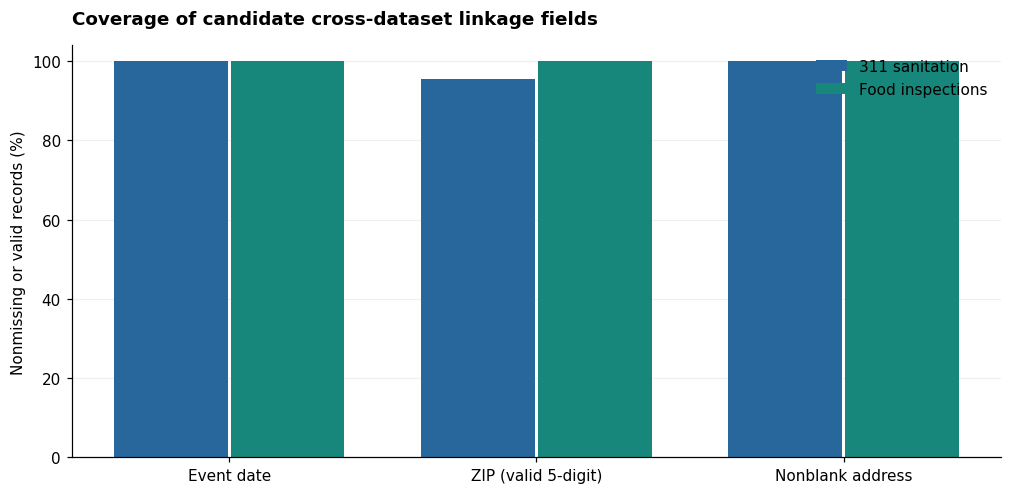

In [2]:
d=quality.copy();idx=np.arange(len(d));fig,ax=plt.subplots();ax.bar(idx-.19,d['311_pct'],.37,label='311 sanitation',color=BLUE);ax.bar(idx+.19,d.food_pct,.37,label='Food inspections',color=TEAL)
ax.set_xticks(idx,d.field.astype(str));ax.set_ylim(0,104);ax.legend(frameon=False);style(ax,'Coverage of candidate cross-dataset linkage fields','Nonmissing or valid records (%)');show()

**Interpretation:** Nonmissing does not guarantee clean matching. ZIP and street address fields are present but may use incompatible conventions; identifiers for individual businesses and 311 complainants are not shared.

### Chart 2 | Both streams exist over time

**Question:** Do the two types of records cover the same historical period?

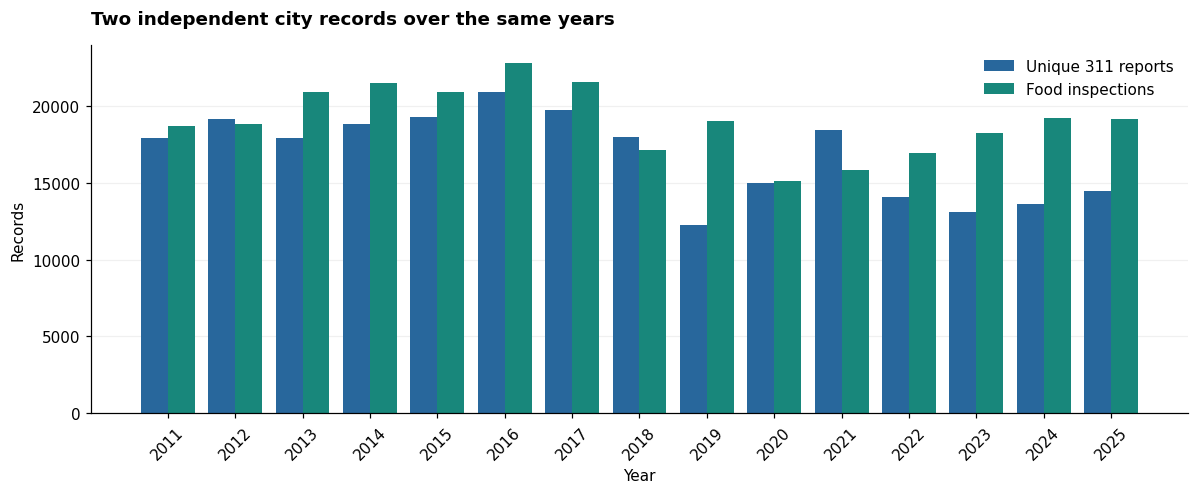

In [3]:
d=annual;fig,ax=plt.subplots(figsize=(11,4.6));idx=np.arange(len(d));ax.bar(idx-.2,d.complaints,width=.4,color=BLUE,label='Unique 311 reports');ax.bar(idx+.2,d.inspections,width=.4,color=TEAL,label='Food inspections');ax.set_xticks(idx,d.year.astype(int),rotation=45);ax.legend(frameon=False);style(ax,'Two independent city records over the same years','Records','Year');show()

**Interpretation:** Long overlapping coverage is promising for analysis, but inspection and complaint counts are different measures with different reporting processes.

### Chart 3 | Exact-address matching coverage by year

**Question:** How consistently can we link food inspection address-years to same-year sanitation reports?

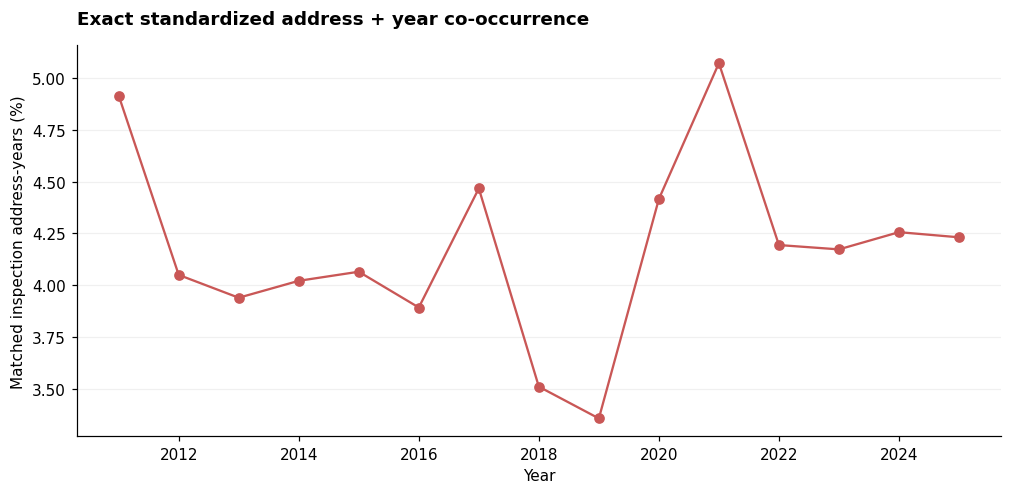

In [4]:
d=matching_year;fig,ax=plt.subplots();ax.plot(d.year,d.match_pct,marker='o',color=RED)
style(ax,'Exact standardized address + year co-occurrence','Matched inspection address-years (%)','Year');show()

**Interpretation:** Conservative exact matches cover a small share of inspection address-years. Better street-address standardization or shared establishment IDs could change apparent coverage, but could also introduce false links.

### Chart 4 | Matching precision vs geographic reach

**Question:** How much does linkage coverage change when moving from ZIP-year to exact address-year?

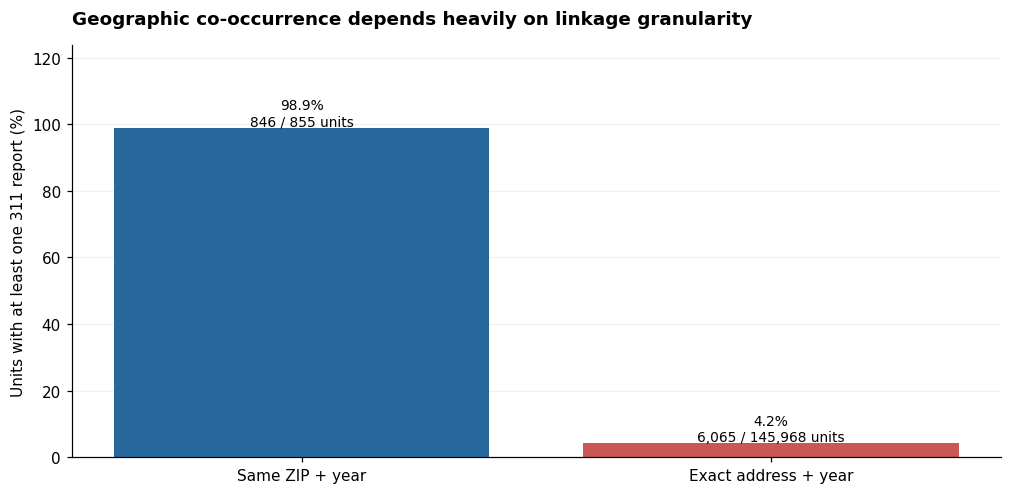

In [5]:
d=coverage.copy();fig,ax=plt.subplots();bars=ax.bar(d.scope,d.percent,color=[BLUE,RED]);
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.7,f'{r.percent:.1f}%\n{r.matched:,} / {r.units:,} units',ha='center',fontsize=9)
ax.set_ylim(0,max(d.percent)*1.25);style(ax,'Geographic co-occurrence depends heavily on linkage granularity','Units with at least one 311 report (%)');show()

**Interpretation:** These percentages use different units of analysis, not competing accuracy scores. Same ZIP-year offers broad ecological coverage but **cannot connect a complaint to a facility**; exact-address-year coverage is narrower, still not proof of causation.

### Chart 5 | Matched vs unmatched inspection outcomes

**Question:** Do co-located reports isolate a different inspection-failure subset?

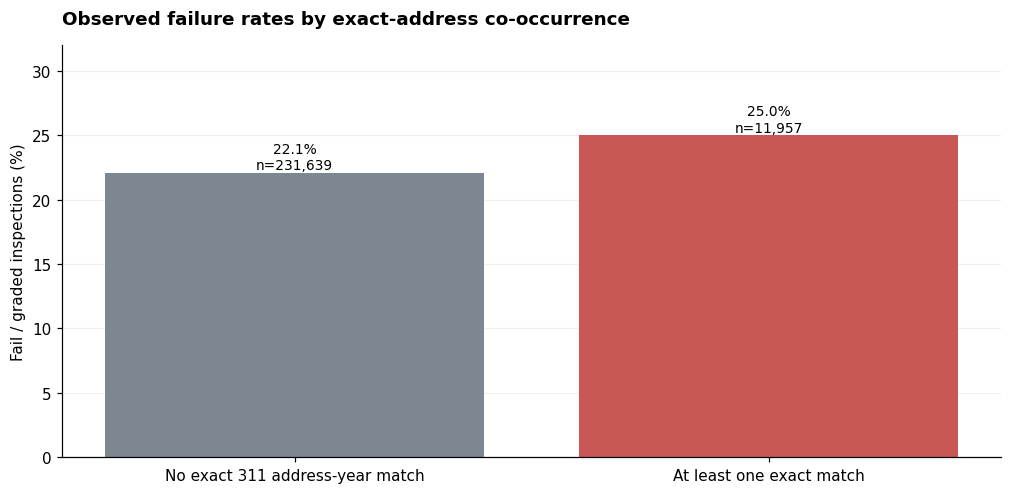

In [6]:
d=matched.copy();d['label']=d.matched.map({False:'No exact 311 address-year match',True:'At least one exact match'});fig,ax=plt.subplots();bars=ax.bar(d.label,d.fail_pct,color=[GREY,RED]);
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.3,f'{r.fail_pct:.1f}%\nn={r.graded:,}',ha='center',fontsize=9)
ax.set_ylim(0,max(d.fail_pct)*1.28);style(ax,'Observed failure rates by exact-address co-occurrence','Fail / graded inspections (%)');show()

**Interpretation:** An apparently useful descriptive distinction is not proof of an actionable warning signal. Selection of establishments and complaint reporting may drive the difference.

### Chart 6 | Can the prototype add predictive value?

**Question:** Does the combined Chicago data improve held-out predictions beyond inspection attributes?

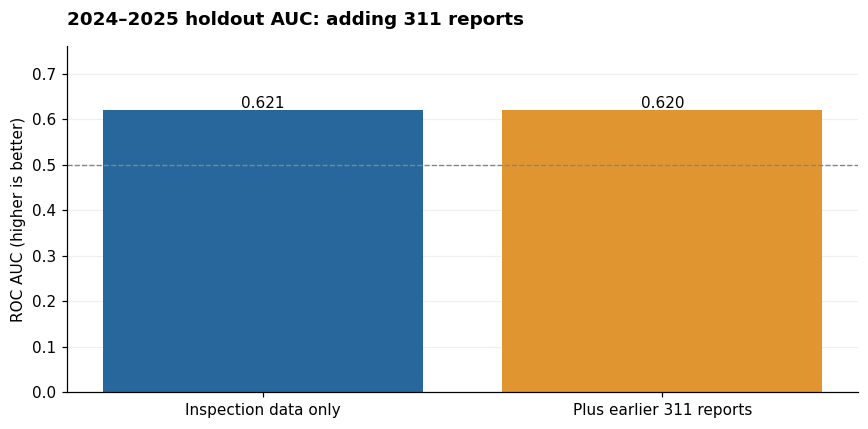

In [7]:
d=pd.DataFrame([{'Model':'Inspection data only','AUC':model_metrics['baseline']['auc']},{'Model':'Plus earlier 311 reports','AUC':model_metrics['with_prior_311']['auc']}]);fig,ax=plt.subplots(figsize=(8,4));bars=ax.bar(d.Model,d.AUC,color=[BLUE,ORANGE]);
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.005,f'{r.AUC:.3f}',ha='center',fontsize=10)
ax.axhline(.5,color=GREY,ls='--',linewidth=.9);ax.set_ylim(0,.76);style(ax,'2024–2025 holdout AUC: adding 311 reports','ROC AUC (higher is better)');show()

**Interpretation:** This prototype does not show predictive improvement from adding recent complaints. A transferable city template should report **null and negative findings** and require local validation before operational use.

## Discussion and responsible claims

**What can actually transfer:** a documented workflow—deduplicate, standardize time and geography, quantify matching coverage, compare rates with proper denominators, evaluate out-of-time holdouts, and report uncertainty. **What has not been demonstrated:** that Chicago is a benchmark for other U.S. cities or that combined 311 data improves food-safety decisions elsewhere. Another city would need comparable fields, locally verified geocoding, governance approvals, and out-of-city validation.

## Key Findings and Business Implications

### Executive takeaway
**Chicago demonstrates a workable *analysis process*, not a validated predictive system or a proven national model.** Its records are substantial and cover overlapping years, but exact-address linkage is limited and 311 inputs did not improve this pilot's predictive accuracy.

### Five evidence-backed findings

1. **Core fields are largely populated (Chart 1).** Event dates were present in **100.0%** of both sources; valid five-digit ZIPs covered **95.5%** of 311 records and **100.00%** of inspection records. These are *presence/validity checks*, not proof that the data can link establishments accurately.
2. **Both streams cover fifteen comparable years (Chart 2).** The two source archives support **2011–2025** comparisons after deduplicating request and inspection IDs. Partial 2010/2026 years are intentionally not treated as complete.
3. **Linkage coverage depends strongly on geography (Charts 3–4).** **846 of 855** ZIP-years (**98.9%**) contained both streams, but only **6,065 of 145,968** inspection address-years (**4.16%**) matched a 311 report. These denominators are **different units of analysis**, not two competing “match accuracy” estimates.
4. **Co-located records show a descriptive difference (Chart 5).** The graded-inspection failure rate was **25.0%** at matched address-years (**n=11,957**) and **22.1%** elsewhere (**n=231,639**). A shared address/year does not demonstrate a complaint was about that restaurant.
5. **Pilot predictive utility is not established (Chart 6).** Held-out ROC AUC was **0.621** for an inspection-only baseline and **0.620** with earlier 311 signals on **31,981** 2024–2025 graded inspections. The combined predictor did **not** improve this evaluation.

### Business / public-service implications

- **Chicago agencies:** share consistent date, location, and where legally appropriate establishment identifiers before attempting operational cross-dataset targeting.
- **Other cities:** reuse the *evaluation checklist* (deduplication, definitions, join coverage, minimum denominators, temporal validation, uncertainty, privacy review), not Chicago's coefficients or ZIP-level rankings.
- **Program leaders:** demand evidence of incremental decision value over existing inspection practices before investing in automated early-warning tools.

### Recommended next steps

1. Define a portable data dictionary specifying incident dates, inspection results, risk categories, facility identifiers, street address and ZIP normalization, and permitted uses.
2. Pilot the same workflow in another city **using that city's own data**, record missingness and linkage coverage, and evaluate predictive value on a held-out future period.
3. Build audit checks for duplicates, failed geocoding, shared or multi-tenant addresses, subgroup performance, privacy, and unintended enforcement bias before any implementation.

### Limits and responsible conclusion

**No city other than Chicago was studied.** High ZIP-year overlap is ecological co-occurrence, not matched business data; low exact-address overlap limits direct inference. This project supports the **potential portability of a transparent method**, not a claim that Chicago already provides a validated template for national food-safety policy.

**Source of values:** `field_quality.csv`, `annual_comparison.csv`, `join_coverage.csv`, `exact_address_year_by_match.csv`, and the notebook's embedded model metrics.
